<a href="https://colab.research.google.com/github/soorbaev/ai-labs/blob/main/campus_knn_class_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Опоздаешь на пару? — k-NN классификация

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('campus-commute-late.csv')

df.head()

,trip_id,day_of_week,commute_mode,distance_km,leave_hour,buffer_minutes,sleep_hours,raining,temperature_c,traffic_index,backpack_kg,phone_battery,woke_late,is_late
0,T0001,Thu,walk,2.38,8,8,8.2,0,20.7,8,4.2,40.0,0,1
1,T0002,Tue,scooter,3.85,16,45,7.3,0,24.1,6,4.6,59.0,0,0
2,T0003,Mon,walk,1.12,9,48,7.5,0,24.0,4,4.9,36.0,0,0
3,T0004,Wed,bike,3.24,16,24,5.8,0,21.7,8,4.7,64.0,0,1
4,T0005,Fri,scooter,6.38,8,15,6.8,0,15.1,8,4.1,64.0,0,1


### Столбцы

| Столбец | Смысл |
|---------|--------|
| `distance_km` | расстояние до кампуса |
| `leave_hour` | час выхода из дома |
| `buffer_minutes` | сколько минут «в запасе» до начала пары |
| `sleep_hours` | сон прошлой ночью |
| `raining` | дождь (0/1) |
| `temperature_c` | температура |
| `traffic_index` | загруженность дороги 1–10 |
| `backpack_kg` | вес рюкзака |
| `phone_battery` | заряд телефона |
| `woke_late` | проспал будильник (0/1) |
| `commute_mode` | walk / bike / scooter / bus |
| `day_of_week` | день |
| **`is_late`** | **цель:** 1 = опоздание, 0 = вовремя |


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   trip_id         380 non-null    object 
 1   day_of_week     380 non-null    object 
 2   commute_mode    380 non-null    object 
 3   distance_km     380 non-null    float64
 4   leave_hour      380 non-null    int64  
 5   buffer_minutes  380 non-null    int64  
 6   sleep_hours     380 non-null    float64
 7   raining         380 non-null    int64  
 8   temperature_c   380 non-null    float64
 9   traffic_index   380 non-null    int64  
 10  backpack_kg     380 non-null    float64
 11  phone_battery   362 non-null    float64
 12  woke_late       380 non-null    int64  
 13  is_late         380 non-null    int64  
dtypes: float64(5), int64(6), object(3)
memory usage: 41.7+ KB


# Подготовка признаков

In [4]:
# Заполняем пропуски в phone_battery
df['phone_battery'] = df['phone_battery'].fillna(df['phone_battery'].median())

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   trip_id         380 non-null    object 
 1   day_of_week     380 non-null    object 
 2   commute_mode    380 non-null    object 
 3   distance_km     380 non-null    float64
 4   leave_hour      380 non-null    int64  
 5   buffer_minutes  380 non-null    int64  
 6   sleep_hours     380 non-null    float64
 7   raining         380 non-null    int64  
 8   temperature_c   380 non-null    float64
 9   traffic_index   380 non-null    int64  
 10  backpack_kg     380 non-null    float64
 11  phone_battery   380 non-null    float64
 12  woke_late       380 non-null    int64  
 13  is_late         380 non-null    int64  
dtypes: float64(5), int64(6), object(3)
memory usage: 41.7+ KB


In [6]:
df['commute_mode'].value_counts()

,count
commute_mode,
bike,114
walk,95
scooter,94
bus,77


In [7]:
df.describe()

,distance_km,leave_hour,buffer_minutes,sleep_hours,raining,temperature_c,traffic_index,backpack_kg,phone_battery,woke_late,is_late
count,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000
mean,3.592368,10.755263,27.376316,6.832632,0.297368,16.111842,5.913158,3.678421,52.815789,0.163158,0.518421
std,1.710061,2.933853,15.125263,1.289060,0.457703,5.896597,1.879015,1.522897,22.443662,0.369997,0.500319
min,0.440000,7.000000,3.000000,3.500000,0.000000,-5.200000,1.000000,0.500000,1.000000,0.000000,0.000000
25%,2.185000,8.000000,14.000000,5.900000,0.000000,12.175000,5.000000,2.600000,37.000000,0.000000,0.000000
50%,3.695000,10.000000,28.500000,6.800000,0.000000,16.300000,6.000000,3.650000,54.000000,0.000000,1.000000
75%,4.985000,13.000000,39.000000,7.700000,1.000000,20.425000,7.000000,4.700000,67.000000,0.000000,1.000000
max,6.480000,17.000000,55.000000,10.000000,1.000000,31.400000,10.000000,7.800000,100.000000,1.000000,1.000000


In [8]:
df.columns

Index(['trip_id', 'day_of_week', 'commute_mode', 'distance_km', 'leave_hour',
       'buffer_minutes', 'sleep_hours', 'raining', 'temperature_c',
       'traffic_index', 'backpack_kg', 'phone_battery', 'woke_late',
       'is_late'],
      dtype='object')

In [9]:
numeric_features = ['distance_km', 'leave_hour',
       'buffer_minutes', 'sleep_hours', 'raining', 'temperature_c',
       'traffic_index', 'backpack_kg', 'phone_battery', 'woke_late']

In [10]:
y = df['is_late']

In [11]:
X_num = df[numeric_features]

In [12]:
X_num.head()

,distance_km,leave_hour,buffer_minutes,sleep_hours,raining,temperature_c,traffic_index,backpack_kg,phone_battery,woke_late
0,2.38,8,8,8.2,0,20.7,8,4.2,40.0,0
1,3.85,16,45,7.3,0,24.1,6,4.6,59.0,0
2,1.12,9,48,7.5,0,24.0,4,4.9,36.0,0
3,3.24,16,24,5.8,0,21.7,8,4.7,64.0,0
4,6.38,8,15,6.8,0,15.1,8,4.1,64.0,0


In [13]:
X_mode = pd.get_dummies(df['commute_mode'], prefix = 'mode') # one-hot encoding

In [14]:
X_mode.head()

,mode_bike,mode_bus,mode_scooter,mode_walk
0,False,False,False,True
1,False,False,True,False
2,False,False,False,True
3,True,False,False,False
4,False,False,True,False


In [15]:
X = pd.concat([X_num, X_mode], axis = 1)

In [16]:
X.head()

,distance_km,leave_hour,buffer_minutes,sleep_hours,raining,temperature_c,traffic_index,backpack_kg,phone_battery,woke_late,mode_bike,mode_bus,mode_scooter,mode_walk
0,2.38,8,8,8.2,0,20.7,8,4.2,40.0,0,False,False,False,True
1,3.85,16,45,7.3,0,24.1,6,4.6,59.0,0,False,False,True,False
2,1.12,9,48,7.5,0,24.0,4,4.9,36.0,0,False,False,False,True
3,3.24,16,24,5.8,0,21.7,8,4.7,64.0,0,True,False,False,False
4,6.38,8,15,6.8,0,15.1,8,4.1,64.0,0,False,False,True,False


In [17]:
print(X.shape)

(380, 14)


# Train / test split

In [18]:
from sklearn.model_selection import train_test_split

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size = 0.25, random_state=42, stratify = y
)

print("train:", X_train.shape, "test:", X_test.shape)

train: (285, 14) test: (95, 14)


# Import KNN

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score # доля верных ответов: кол-во верных ответов / общее количество

In [21]:
# KNN без Scaler

knn = KNeighborsClassifier(n_neighbors= 5)
knn.fit(X_train, y_train)

# predicitions
pred = knn.predict(X_test)


print(pred)

[1 0 0 0 0 0 0 1 0 1 0 1 1 0 0 0 1 0 1 1 0 1 1 0 0 0 0 0 1 0 0 1 0 0 0 1 1
 1 0 1 1 1 1 0 1 0 0 0 1 0 1 1 1 0 0 0 1 0 0 0 1 0 1 0 0 1 0 0 1 0 0 0 0 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 1 0 0 0 0 1 0 0]


In [22]:
accuracy = accuracy_score(y_test, pred)

print("k=5 accuracy WITHOUT scaling:", accuracy)

k=5 accuracy WITHOUT scaling: 0.5789473684210527


# Scaling

`distance_km`~ единицы
`phone_battery` ~ дестяки - сотни

Без масштабирования чаще всего решает признак с большим размером

In [23]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.fit_transform(X_test)

knn = KNeighborsClassifier()
knn.fit(X_train_s, y_train)

pred = knn.predict(X_test_s)

accuracy = accuracy_score(y_test, pred)

print("k=5 accuracy WITH scaling:", accuracy)

k=5 accuracy WITH scaling: 0.7684210526315789


In [24]:
X_train_s[:10]

array([[-1.39720769, -0.61702628,  0.83599764, -1.76237796, -0.66286797,
        -0.58235031, -1.5941138 , -0.98547381,  0.98765302, -0.44438608,
        -0.60302269, -0.49451136, -0.5976143 ,  1.62906297],
       [-1.39720769, -1.27688553,  0.31105283, -0.4119555 ,  1.50859606,
        -0.7372532 ,  1.07523069, -0.98547381, -0.05235751, -0.44438608,
        -0.60302269, -0.49451136, -0.5976143 ,  1.62906297],
       [ 1.31851259,  0.70269222, -0.8044549 ,  2.52719927,  1.50859606,
        -0.84052179,  1.60909959, -0.04882767,  0.26416743,  2.25029549,
        -0.60302269,  2.02219824, -0.5976143 , -0.61384981],
       [ 1.52336218,  0.04283297,  0.24543472, -0.65026535,  1.50859606,
        -0.56513888,  2.14296849,  0.62020529, -0.27844676, -0.44438608,
        -0.60302269, -0.49451136, -0.5976143 ,  1.62906297],
       [ 0.63958252, -0.9469559 ,  1.16408814, -0.80913858,  1.50859606,
        -1.40849905, -0.526376  , -0.98547381, -1.04715019, -0.44438608,
        -0.60302269, -0.49

# Confusion Matrix

строки - истина

столбцы - прогноз

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

[[37  9]
 [13 36]]


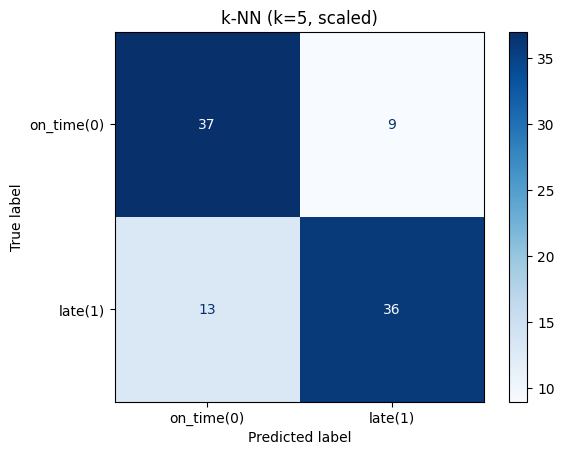

In [26]:
cm = confusion_matrix(y_test, pred)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels = ['on_time(0)', 'late(1)'])
disp.plot(cmap='Blues')
plt.title('k-NN (k=5, scaled)')
plt.show()

# Задания на самостоятельную работу

1. Переберите несколько значений `k` и сравните `accuracy` на тесте. Постройте график `k` и `accuracy` которая ей соответствует

In [27]:
# Очищаем датасет от пропусков
df_clean = df.dropna().copy()

# Выбираем основные признаки для модели и целевую переменную
features = ['distance_km', 'leave_hour', 'buffer_minutes', 'sleep_hours', 'raining', 'temperature_c', 'traffic_index', 'backpack_kg', 'phone_battery', 'woke_late']
X = df_clean[features]
y = df_clean['is_late']

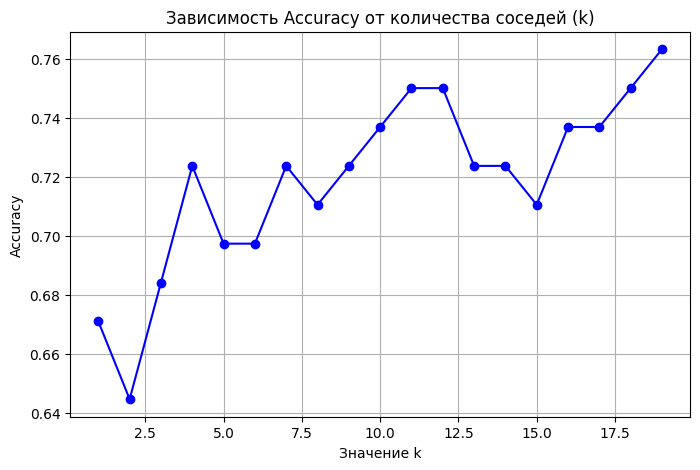

Лучшее k: 19, Максимальная accuracy: 0.7632


In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Делим данные и масштабируем
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Перебираем k от 1 до 19
k_values = range(1, 20)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    preds = knn.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, preds))

# 3. Строим график
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='b')
plt.title('Зависимость Accuracy от количества соседей (k)')
plt.xlabel('Значение k')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

best_k = k_values[np.argmax(accuracies)]
print(f"Лучшее k: {best_k}, Максимальная accuracy: {max(accuracies):.4f}")

### Задание A

Добавьте one-hot для `day_of_week` в матрицу `X`, заново сделайте split + scaler + k-NN (`k=5`).  
Сравните accuracy с нашей моделью выше.


In [29]:
# Добавляем день недели через One-Hot Encoding
X_a = pd.get_dummies(df_clean[features + ['day_of_week']], columns=['day_of_week'], drop_first=False)

X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(X_a, y, test_size=0.2, random_state=42)

scaler_a = StandardScaler()
X_train_a_scaled = scaler_a.fit_transform(X_train_a)
X_test_a_scaled = scaler_a.transform(X_test_a)

knn_a = KNeighborsClassifier(n_neighbors=5)
knn_a.fit(X_train_a_scaled, y_train_a)
acc_a = accuracy_score(y_test_a, knn_a.predict(X_test_a_scaled))

print(f"Accuracy с One-Hot для дней недели (k=5): {acc_a:.4f}")

Accuracy с One-Hot для дней недели (k=5): 0.6974


### Задание B

Обучите k-NN только на **двух** признаках: `distance_km` и `buffer_minutes` (со scaling).  
Какой accuracy? Почему модель слабее или неожиданно сильная?


In [30]:
# Берем только два признака
X_b = df_clean[['distance_km', 'buffer_minutes']]

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_b, y, test_size=0.2, random_state=42)

scaler_b = StandardScaler()
X_train_b_scaled = scaler_b.fit_transform(X_train_b)
X_test_b_scaled = scaler_b.transform(X_test_b)

knn_b = KNeighborsClassifier(n_neighbors=5)
knn_b.fit(X_train_b_scaled, y_train_b)
acc_b = accuracy_score(y_test_b, knn_b.predict(X_test_b_scaled))

print(f"Accuracy только на 2 признаках (k=5): {acc_b:.4f}")

Accuracy только на 2 признаках (k=5): 0.7105
